# <font color='blue'>Machine Learning Coursework 1 (Midterm)</font> 

This coursework is worth 100 marks, amounting to 50% of the final course mark.

For the coursework, you are allowed to use `sklearn` except where a manual implementation is explicitly requested. You will need to choose a model class and a dataset, implement code that displays a plot of the relationship between features, train a series of models on the original data, a noised version of it, as well as one with only a limited amount of features. You will also have to provide your own implementation of confusion matrices and common metrics like accuracy, and use them in your training runs. You will then have a choice between various research directions to expand the required experiments.

The purpose of this coursework is to help you:
- Get familiar with **common python modules / functions** used for ML in python.
- Get practical experience **implementing** ML methods in python.
- Get practical experience regarding **parameter selection** for ML methods.

### Notes

- References are an important aspect of your CW; please use citations to support your arguments.  
- Remember to comment all of your code ([see here for tips](https://stackabuse.com/commenting-python-code/)). You can also make use of Jupyter Markdown, where appropriate, to improve the layout of your code and documentation.
- Please add docstrings to all of your functions (so that users can get information on inputs/outputs and what each function does by typing SHIFT+TAB over the function name). For more detail on python docstrings, [see here](https://numpydoc.readthedocs.io/en/latest/format.html).
- At any point feel free to create new markdown or code cells to organise your answers. You may also include additional headings if necessary, respecting the notebook hierarchy (for instance, if the current question is a third-level heading `###`, only use fourth- or fifth-level ones (`####`, `#####`, respectively) in your answer. Remember your reader: your goal should always be _concision_ and _readability_!
- Always save your notebook when you are done (this is not automatic)!
- Upload your completed notebook as is (`.ipynb` file) using the VLE.

Plagiarism: please make sure that the material you submit has been created by you. Any sources you use for code should be properly referenced. Your code will be checked for plagiarism using appropriate software.

### Marking 

The grades in this coursework are allocated approximately as follows: 


| section                                            | mark  |  
|:---------------------------------------------------|-------|
| 1. Dataset                                         | 3     | 
| 2. Data exploration                                | 7     |
| 3. Training                                        | 30    | 
| 4. Analysis                                        | 10    | 
| 5. Self-directed research                          | 40    |  
| Document quality: language, comments & code        | 10    |
| Total available                                    |**100**|  

## <font color='blue'>1. Dataset [3 pts]</font> 

In this coursework we are going to be working with **one** toy dataset from `sklearn` dataset, of your choice:
- iris;
- diabetes;
- wine;
- breast cancer.

You can find the API [here](https://scikit-learn.org/stable/datasets/toy_dataset.html). 

### <font color='blue'>1.1 Introduction [2 pts]</font>

In the following cell, briefly describe:
- what kind of data the dataset contains;
- what kind of ML approach it is suited for (classification, regression, clustering, etc.);
- what are the features available.

#### Introduction to the Wine Dataset
For this coursework, I have selected the Wine dataset from scikit-learn. This dataset contains the results of chemical analyses performed on wines grown in the same region in Italy by three different cultivators. For each wine sample, thirteen numerical measurements were taken, representing the concentrations of various chemical constituents.

This dataset is a typical example for a classification task in supervised machine learning. The goal is to predict the class of each wine sample (corresponding to one of the three cultivators) based on the provided features.

The available features describing each wine are:
- Alcohol: alcohol content
- Malic acid: concentration of malic acid
- Ash: mineral content
- Alcalinity of ash: alcalinity of the ash
- Magnesium: magnesium concentration
- Total phenols: total phenolic content
- Flavanoids: flavonoid content
- Nonflavanoid phenols: non-flavonoid phenol content
- Proanthocyanins: proanthocyanin content
- Color intensity: intensity of the wine's color
- Hue: shade of the wine color
- OD280/OD315 of diluted wines: spectrophotometric measurement related to protein content
- Proline: proline content   

The target variable, "class," indicates the type of wine and is encoded as one of three classes: class_0, class_1, or class_2.<sup>1</sup>

### <font color='blue'>1.2 Dataset loading [1 pts]</font>

In the following cell(s), import the relevant libraries, then import one dataset of your choice using the `sklearn` `datasets` API, and create two variables to store your data, `X`, and target, `y`. After that, create train and test splits.

In [82]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

wine = datasets.load_wine()

# X is the data matrix containing the features
X = wine.data
print(f"Shape of X: {X.shape}")

# y is the vector containing the targets
y = wine.target
print(f"Shape of y: {y.shape}")

# Save 20% for testing using random splitting
X_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2)

# Take a look into the data
print(f"\nX_train shape and first rows: {X_train.shape}\n{X_train[:1, :]}")
print(f"\nx_test shape and first rows: {x_test.shape}\n{x_test[:1, :]}")

print(f"\ny_train shape and first rows: {y_train.shape}\n{y_train[0]}")
print(f"\ny_test shape and first rows: {y_test.shape}\n{y_test[0]}")

Shape of X: (178, 13)
Shape of y: (178,)

X_train shape and first rows: (142, 13)
[[ 14.13   4.1    2.74  24.5   96.     2.05   0.76   0.56   1.35   9.2
    0.61   1.6  560.  ]]

x_test shape and first rows: (36, 13)
[[1.328e+01 1.640e+00 2.840e+00 1.550e+01 1.100e+02 2.600e+00 2.680e+00
  3.400e-01 1.360e+00 4.600e+00 1.090e+00 2.780e+00 8.800e+02]]

y_train shape and first rows: (142,)
2

y_test shape and first rows: (36,)
0


## <font color='blue'>2. Data exploration [7 pt]</font> 

The first part of tackling any ML problem is visualising the data in order to understand some of the properties of the problem at hand.  When there are only a small number of classes and features, it is possible to use scatter plots to visualise interactions between different pairings of features. 

### <font color='blue'>2.1 Visualisation I: features [7 pt]</font>

Your first task is to recreate a "scatter matrix" (or "pair plot") for the dataset you chose, similar to the example given using the Iris dataset, with each off-diagonal subplot showing the interaction between two features (a pairwise scatter plot), and each of the classes represented as a different colour. The on-diagonal subplots (representing a single feature) should show a distribution (or histogram) for that feature.   

#### <font color='blue'>2.1.1 Code: feature selection [2 pt]</font>

As a first step, you will create a copy of your dataset keeping only three features from the dataset. The choice of the three features depends on the chosen dataset: provide the reasons for your choice in your analysis below. Feature selection opens up a fairly wide field of experimentations, and you will be able to return to this later in this coursework.

There are various ways in which this selection of features can be done. Here is one:

1. Once the dataset is loaded, print the list of its attribute `feature_names`.
2. Create a `pandas` `DataFrame` using the `data` attribute of your dataset, and the `feature_names` attribute as `columns`.
3. Create a list `selected_features` containing three names (as strings) from the list of `feature_names` you printed earlier.
4. Using that `selected_features` as an index, select the columns from your dataframe, and store its `values` attribute into `X`. You can store the `target` attribute of your dataset variable into `y`.

In [76]:
import pandas as pd
X_wine_df = pd.DataFrame(wine.data, columns = wine.feature_names)
X_wine_df.head(3)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0


In [95]:
# create a copy of your dataset containing only three features
'''
For now, I have selected the following three features:
1. Alcohol: this is a key characteristic of wines and may be a strong indicator of the class
2. Colour Intensity: this feature is easier to distinguish visually and could reflect differences between classes
3. Proline: this is usually an important property in wine analysis and may help differentiate wine types.
'''
X_alc_colour_proline_df = X_wine_df[ ['alcohol', 'color_intensity', 'proline'] ].copy()
X_alc_colour_proline_df.head(3)

,alcohol,color_intensity,proline
0,14.23,5.64,1065.0
1,13.20,4.38,1050.0
2,13.16,5.68,1185.0


In [96]:
y_alc_colour_proline_df = pd.DataFrame(wine.target, columns = ["target"])
print(y_alc_colour_proline_df['target'].unique())
y_alc_colour_proline_df.head(3)

[0 1 2]


,target
0,0
1,0
2,0


In [97]:
X_alc_colour_proline_train, X_alc_colour_proline_test, y_alc_colour_proline_train, y_alc_colour_proline_test = train_test_split(X_alc_colour_proline_df, y_alc_colour_proline_df, test_size = 0.2)

# Take a look into the data
print(f"\nX_train shape and first row: {X_alc_colour_proline_train.shape}\n{X_alc_colour_proline_train.head(1)}")
print(f"\nx_test shape and first row: {X_alc_colour_proline_test.shape}\n{X_alc_colour_proline_test[:1]}")

print(f"\ny_train shape and first row: {y_alc_colour_proline_train.shape}\n{y_alc_colour_proline_train.iloc[0]}")
print(f"\ny_test shape and first row: {y_alc_colour_proline_test.shape}\n{y_alc_colour_proline_test.iloc[0]}")


X_train shape and first row: (142, 3)
    alcohol  color_intensity  proline
60    12.33             3.27    680.0

x_test shape and first row: (36, 3)
     alcohol  color_intensity  proline
130    12.86              4.1    630.0

y_train shape and first row: (142, 1)
target    1
Name: 60, dtype: int64

y_test shape and first row: (36, 1)
target    2
Name: 130, dtype: int64


#### <font color='blue'>2.1.2 Code: plotting function [3 pt]</font>

You should create a function that, given data X and labels y, plots this grid. The function should be invoked something like this:

```python
my_plot_grid(X, y, ...)
```
    
where `X` is your training data and `y` are the labels (you may also supply additional optional arguments). You can use an appropriate library to help you create the visualisation. You might want to code it yourself using matplotlib functions `scatter` and `hist` - however, this is not strictly necessary here, so try not to spend too much time on this. 

In [98]:
import seaborn as sns
import matplotlib.pyplot as plt


# define plotting function
def my_plot_grid(X, y):
    """
    Plots a scatter matrix (pair plot) for a given set of features (X) and labels (y).

    - Each off-diagonal subplot shows a scatter plot of a feature pair, colored by class.
    - Each diagonal subplot shows a histogram of a single feature, colored by class.

    Parameters
    ----------
    X : pandas.DataFrame
        DataFrame containing the features to plot.
    y : pandas.Series or array-like
        Labels/classes for each sample. Used for color coding.

    Returns
    -------
    None
        Displays the scatter matrix plot.
    """
    df = X.copy()
    df["target"] = y.values
    sns.pairplot(df, hue="target", diag_kind="hist")
    plt.show()

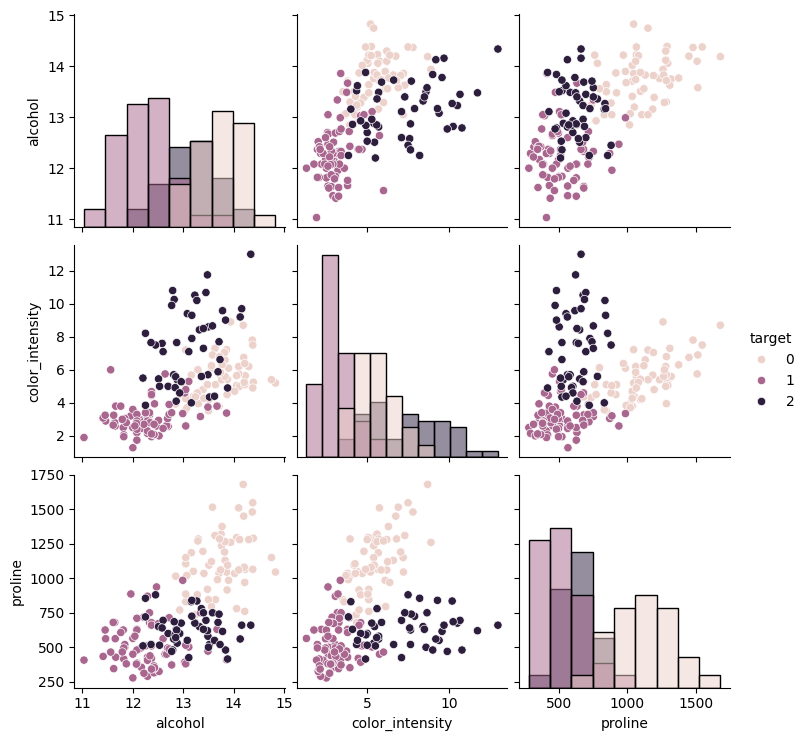

In [99]:
# run the plotting function
my_plot_grid(X_alc_colour_proline_df, y_alc_colour_proline_df)

#### <font color='blue'>2.1.3 Analysis [2 pt]</font>

What do you observe? Provide a brief analysis of your plot.

##### Histogram
From the histograms, we observe that:
- class 0 tends to have higher values for both alcohol and proline
- class 1 generally exhibits lower values across all three features: alcohol, color intensity and proline
- class 2 typically occupies the intermediate range for alcohol and proline
The clear ordering and minimal overlap between classes suggest that these three features are well separable, making them strong candidates for use in classification.

##### Scatter plot
Most feature pairs show clear clustering for each class, further indicating that these features are effective in accurately separating the classes in a classification model.
For example:
- The scatter plot of alcohol vs. proline shows class 0 clustered at higher values, while class 1 is concentrated at the lower end, and class 2 lies in between, demonstrating a strong separation

## <font color='blue'>3. Model I [30 pt]</font> 

### <font color='blue'>3.1. Introduction [3 pt]</font>

Choose **one** model class from the course (up to Topic 5 inclusive). Briefly introduce that class, its strengths and weaknesses, and its relevance for the problem and dataset at hand.

#### Answer
I have selected supervised k-Nearest Neighbors (KNN) classification for this task. The principle behind this method is to find a predefined number of training samples closest in distance to a new data point and predict its label based on those neighbors. Neighbors-based classification is a type of instance-based, or non-generalizing, learning: instead of building an internal model, it simply stores the training data and bases predictions on it. Classification is determined by a simple majority vote among the nearest neighbors. For measuring distance, I will use the standard Euclidean distance, and the value of k will be treated as a hyperparameter that I can experiment with. <sup>2</sup>

Advantages:
- Simple and fast (no training required)
- Capable of handling multi-class problems
- Does not require prior knowledge of the data distribution

Disadvantages:
- Slow for large datasets; however, this is not a concern here, as the dataset contains only 178 rows
- Does not handle irrelevant features well; I plan to address this by experimenting with different selected features
- Very sensitive to feature scaling, especially in high-dimensional spaces; I will limit its use to the three selected features, which is appropriate for KNN

Given these considerations, KNN is a suitable and effective choice for the wine classification task in this coursework.

### <font color='blue'>3.2 Model evaluation [10 pts]</font>

In the cell below, implement **your own** classifier evaluation code as reusable functions, not using `sklearn`. This should include some way of **calculating common metrics**, like 
- **accuracy, precision, recall and F1 score** as well as **confusion matrices** for classifiers,
- or the **mean squared error**, **root mean squared error**, **mean absolute error** and the **$R^2$ score** for regressors. 

Write some additional code that lets you display the output of your confusion matrices in a useful and easy-to-read manner.

You might want to test your functions on some test data, and compare the results to the `sklearn` library versions. 

In [106]:
import numpy as np

def my_conf_mat(y_test,y_pred,classno):
    """
    Computes the confusion matrix for multi-class classification.

    Parameters
    ----------
    y_test : array-like of shape (n_samples,)
        True class labels.
    y_pred : array-like of shape (n_samples,)
        Predicted class labels.
    classno : int
        Number of unique classes.

    Returns
    -------
    conf_matrix : numpy.ndarray of shape (classno, classno)
        Confusion matrix where entry [i, j] indicates the number of times 
        class i (actual) was predicted as class j.
    """
    conf_maxtrix = np.zeros((classno,classno))
    for i in range(len(y_test)):
        conf_maxtrix[y_test[i]][y_pred[i]]+=1
    return conf_maxtrix

def print_conf_mat(cm, classno, class_labels = None):
    """
    Prints the confusion matrix with class labels using pandas DataFrame.

    Parameters
    ----------
    cm : numpy.ndarray
        Confusion matrix (n_classes x n_classes).
    class_labels : list of str, optional
        List of class names to use as labels for rows and columns.
        If None, integer labels 0 ... n_classes-1 are used.
    """
    if class_labels is None:
        class_labels = [str(i) for i in range(classno)]
    
    df_cm = pd.DataFrame(cm, index=[f"Actual {cl}" for cl in class_labels],
                             columns=[f"Pred {cl}" for cl in class_labels])
    print("\nConfusion Matrix:")
    print(df_cm)

def my_accuracy(y_test, y_pred):
    """
    Computes the accuracy score for classification.
    Accuracy is the proportion of correct predictions out of all predictions made.

    Parameters
    ----------
    y_test : array-like of shape (n_samples,)
        True class labels.
    y_pred : array-like of shape (n_samples,)
        Predicted class labels.

    Returns
    -------
    accuracy : float
        The accuracy of the predictions: the fraction of correctly predicted labels.
    """
    return sum(np.where(y_test == y_pred, 1, 0)) / len(y_test)

def my_precision(y_test, y_pred, classno):
    """
    Computes the precision score for each class in multi-class classification.

    Precision for a class is the proportion of correct positive predictions (true positives)
    out of all predictions made for that class (true positives + false positives).

    Parameters
    ----------
    y_test : array-like of shape (n_samples,)
        True class labels.
    y_pred : array-like of shape (n_samples,)
        Predicted class labels.
    classno : int
        Number of unique classes.

    Returns
    -------
    precision : numpy.ndarray of shape (classno,)
        Precision score for each class, where precision[i] is the precision for class i.
    """
    classes = np.unique(y_test)
    precision = np.zeros(classes.shape)

    M = my_conf_mat(y_test, y_pred, classno)
    for i in range(classno):
        precision[i] = M[i][i] / np.sum(M[:,i])
    return precision

def my_recall(y_test,y_pred, classno):
    """
    Computes the recall score for each class in multi-class classification.

    Recall for a class is the proportion of correct positive predictions (true positives)
    out of all actual instances of that class (true positives + false negatives).

    Parameters
    ----------
    y_test : array-like of shape (n_samples,)
        True class labels.
    y_pred : array-like of shape (n_samples,)
        Predicted class labels.
    classno : int
        Number of unique classes.

    Returns
    -------
    recall : numpy.ndarray of shape (classno,)
        Recall score for each class, where recall[i] is the recall for class i.
    """
    classes = np.unique(y_pred)
    recall = np.zeros(classes.shape) 
   
    M = my_conf_mat(y_test, y_pred, classno)
    for i in range(classno):
        recall[i] = M[i][i] / np.sum(M[i])
    return recall

# Definition taken from here: 
def my_f1_score(y_test, y_pred, classno):
    """
    Computes the F1 score for each class in a multi-class classification problem.

    The F1 score for a class is the harmonic mean of its precision and recall,
    and is calculated as:
        F1 = 2 * TP / (2 * TP + FP + FN)
    where TP is the number of true positives, 
    FP is the number of false positives, 
    and FN is the number of false negatives for each class.
    Reference: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html

    Parameters
    ----------
    y_test : array-like of shape (n_samples,)
        True class labels.
    y_pred : array-like of shape (n_samples,)
        Predicted class labels.
    classno : int
        Number of unique classes.

    Returns
    -------
    f1 : numpy.ndarray of shape (classno,)
        F1 score for each class, where f1[i] is the F1 score for class i.
    """
    cm = my_conf_mat(y_test, y_pred, classno)
    f1 = np.zeros(classno)
    for i in range(classno):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        denom = 2*TP + FP + FN
        f1[i] = (2*TP) / (denom) if denom != 0 else 0.0
    return f1

def my_evaluate_classifier(model, X_test, y_test, class_labels = None, model_name = ""):
    """
    Evaluates a classifier using the custom metric functions.
    Prints confusion matrix and common metrics.
    
    Parameters
    ----------
    model : fitted classifier (must implement .predict)
    X_test : features for testing
    y_test : true test labels
    class_labels : optional list of class label names
    model_name : optional string to print (e.g., 'KNN', 'Decision Tree')
    """
    y_pred = model.predict(X_test)
    classno = len(np.unique(y_test))
    
    cm = my_conf_mat(y_test, y_pred, classno)
    acc = my_accuracy(y_test, y_pred)
    prec = my_precision(y_test, y_pred, classno)
    rec = my_recall(y_test, y_pred, classno)
    f1 = my_f1_score(y_test, y_pred, classno)

    print(f"----- {model_name} Evaluation -----")
    print_conf_mat(cm, classno, class_labels)
    print(f"Accuracy:  {acc:.3f}")
    print(f"Precision: {prec}")
    print(f"Recall:    {rec}")
    print(f"F1 Score:  {f1}\n")

### <font color='blue'>3.3 Training I [2 pt]</font> 

Instantiate the model, and fit that model to your training data. Use the original dataset with all features, and report its performance, using your own functions defined in _3.2_ to collect and/or print metrics and the confusion matrix.

### <font color='blue'>3.4 Training II: Noisy data [5 pt]</font>

When data are collected under real-world settings they usually contain some amount of noise that makes classification more challenging.

Your task is to conduct experiments showing how adding noise to your data affects model performance.

#### Code

First, create a function that takes in your original dataset as well as noise parameters (mean and standard deviation for Gaussian noise, for instance), and that returns a copy of your dataset perturbed with some noise:

1. Define a random seed (for reproducibility)
2. Pass the random seed to `numpy`
3. Create a copy of your dataset with added noise.
4. Return the perturbed dataset and the targets.

```python
X_perturbed, y = dataset_perturbation(X, y, mean, std)
```

Then split the perturbed data as in section *1*.

#### Code

Train one model with Gaussian noise of mean `0` and std `0.5` and report its performance, using your own functions defined in _3.2_ to collect and/or print metrics and the confusion matrix.

### <font color='blue'>3.5 Training III: Feature selection [5 pt]</font>

In real-world problems, it is exceedingly rare that the features of a dataset are fully uncorrelated, and/or exert the same influence on the predictions of our model. Studying the impact of various features, and various feature subsets, can deepen our understanding of the problem at hand and yield better performance.

Coming back to the topic of feature selection: wrap the code you created for feature selection in a function that takes in as arguments the original dataset and a list of feature names (you can add additional arguments after that if needed):

```python
X_selection, y = feature_selection(X, y, ['feature 1 name', ...], options)
```

Your task is to conduct experiments showing how selecting only certain features (or keeping them all) affects the performance of your model.

When faced with a large number of features, some external knowledge about the dataset, and/or additional data exploration/visualisation, is often unavoidable. Give a brief justification for your choice of features.

#### Answer

#### Code

Create a copy of your dataset with only a selected amount of features.

#### Code

Train one model on the dataset containing only the selected features and report its performance, using your own functions defined in _3.2_ to collect and/or print metrics and the confusion matrix.

### <font color='blue'>3.6 Training IV: Beyond the train and test split [5 pt]</font> 

Explain the limitation arising when using only a train/test split, when comparing various models. What methods provide a more robust way to evaluate models?

#### Answer

#### Code

Implement the proposed improvement to the handling of your data, and perform a training run using your implementation. Report the performance, using your own functions defined in _3.2_ to collect and/or print metrics and the confusion matrix.

## <font color='blue'>4. Analysis [10 pt]</font> 

Present and analyse the results of the training above. 

### <font color='blue'>4.1 Results [1 pts]</font>

Present the performance of your training runs in a clear and succinct way.

This can be done in markdown or programmatically (storing results in a data structure during training runs and displaying its contents here).

### <font color='blue'>4.2 Analysis & Comparison [9 pts]</font>

Analyse your results, comparing the performance of the various training runs (vanilla, with noise, with feature selection), and offering your interpretation of the observed phenomena. It is also good to offer suggestions for further experiments, that in your view could lead to better performance or a deeper understanding.

You are free to organise this section as you see fit. However, it is recommended to take extra care to make it clean and orderly, subdivising it into sections using markdown headings, for better readability. Feel free to use plots if relevant.

#### Answer

## <font color='blue'>5. Self-directed research [40 pt]</font> 

To obtain additional marks, pick one or more options below to flesh out and expand your experiments. As you can see, the marks below are significantly harder to obtain (require more work) than the first 50.

It is advised to keep the legibility and clarity of your coursework when adding new sections, so that the overall structure of the coursework remains coherent.

- Additional **visualisation and data exploration** <font color='blue'>(up to 4 pts)</font>: create a new section, *2.2 Visualisation II: additional plots*, and use relevant visualisation or plotting tools to deepen your analysis of the chosen dataset. Note that only producing a plot or visualisation will not yield many marks on its own. Those should be present to serve a greater purpose: that of understanding (the underlying structure of your data, and the behaviour of your models).
- **Advanced validation techniques** and/or **hyperparameter search** <font color='blue'>(up to 6 pts)</font>: develop your own code experimenting with a different validation technique you implemented in _3.6 Training IV: Beyond the train and test split_ (in plain `numpy`, without the use of `sklearn`, except to compare its behaviour to your code, assessing the correctness of your code). For this, create one or more sections in _3_ (for example: _3.7_) with your code and analysis.
  - In the case of k-fold cross-validation, you would implement a function like:
    ```python
    
      kfold_results = kfold_cross_validation(X, y, k=5, options, my_seed)
      
    ```
    For each fold, your function should split the dataset into a training and validation set and print the the appropriate metrics on the validation set. The final performance should be an average of the accuracies of each fold.
  - For iterated k-fold with shuffling, several runs of the k-fold algorithm are performed on shuffled versions of the original dataset.
  - For nested k-fold cross-validation, multiple values for one or more hyperparameters (such as the number of neighbours in the k-NN algorithm, the depth in decision trees, the number of selected principal components in PCA, the strength of regularisation, etc.) are tested within each fold, and the value with the best validation performance is selected. This allows you to identify which hyperpameters to choose for your model.

  Marks can be gained for the correctness of your implementation, and for your analysis of your results, including a discussion of the relevance of this technique for the problem at hand.
- **Additional noise experiments** <font color='blue'>(up to 6 pts)</font>: experiment with various degrees of noise, and/or with `uniform` noise as well as Gaussian. Expand the sections _3.4 Training II: Noisy data_ and your analysis in _4._ accordingly. You can also add a _2.3 Visualisation III: noise_ section in _2_, creating plots showing the impact of noise. Marks can be obtained for:
  - adding functionalities to your `dataset_perturbation` function;
  - automating the experiment process (using for instance a `for` loop, and reporting all the results at the end in a succinct way, and/or creating a plot);
  - relevant analysis of your results, including a discussion of the relevance of this technique for the problem at hand.
  - data exploration and visualisation of noisy data. Only producing plots of the noisy data will not gain many marks: your goal should be to provide the reader with another, perhaps more intuitive, way to understand the results of your training run with noise.
- **Additional feature selection experiments**  <font color='blue'>(up to 6 pts)</font>: experiment with various features subsets. Expand the sections _3.5 Training III: Feature selection_ and your analysis in _4_ accordingly. You can also add a _2.4 Visualisation IV: feature selection_ section in _2_, creating plots showing the impact of noise. Marks can be obtained for:
  - studying the dataset (external knowledge allowing you to make a reasonable guess as to which feature subsets might be the most appropriate);
  - streamlining the feature selection process (creating a data structure containing various subsets beforehand, or randomly selecting features);
  - automating the experiment process (using for instance a `for` loop, and reporting all the results at the end in a succinct way, and/or creating a plot);
  - relevant analysis of your results, including a discussion of the relevance of this technique for the problem at hand.
  - data exploration and visualisation of feature selection. This would extend and complement _2.1 Visualisation I: features_: your goal should be to provide the reader with a more in-depth visual analysis of the relationship between features in your chosen dataset.
- **Manual implementations of model algorithm** <font color='blue'>(up to 4 pts)</font>: the exploration, for your own learning, and that of your reader(s), of the inner workings of the chosen model class without the use of `sklearn` (e.g. in plain `numpy`). For instance, you can manually implement the k-NN algorithm, implementing various distance functions separately (`euclidean`, `manhattan`, etc.), and perhaps also a function that uncovers the nearest neighbour(s) to a given vector, then using those in a function that takes in your training data, training targets, validation data, as well as various options (such as `k`, the number of neighbours, and perhaps a list of one or more distances), and returns the predictions:
  ```python
    y_val = k_NN(X_train, y_train, X_val, options)
    
  ```
  It can be advantageous in these cases to perform comparisons with the API version in terms of performance, speed, memory footprint, as well as implementing checks to guarantee that your implementation is bug-free.
- Additional **metrics**  <font color='blue'>(up to 4 pts)</font>: research additional metrics related to the problem at hand on the `sklearn` documentation  (classification, regression, ...), implement them manually, using the reference `sklearn` implementation to check the validity of your results. Make sure to accompany your implementation with an introduction and analysis showing why this metric might be relevant, what are its strengths and weaknesses, and how the results compare with, or complement, the other metrics you already have.
- **Additional model class** <font color='blue'>(up to 10 pts)</font>: select *one* different model class from the one you chose initially, create a new section *Model II*, and run the similar experiments as with your first chosen class. Make sure to report your results in *4*, comparing this new model class to the original one.

## <font color='blue'>6. References </font> 
<sup>1</sup> https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-dataset  
<sup>2</sup> https://scikit-learn.org/stable/modules/neighbors.html#nearest-neighbors-classification